# **Section 1: Data Acquisition & Initial Data Preparation**
- - -

## 1.1: Preparing the Analysis Environment
- Before beginning the volcano eruption prediction project, we ensure that our computational environment contains all necessary Python libraries.  
- This step supports the full progression of the Data Science Lifecycle - from data acquisition to modeling and interpretation.


In [34]:
pip install numpy pandas matplotlib seaborn plotly folium geopandas shapely pyproj fiona scikit-learn openpyxl missingno xgboost

Note: you may need to restart the kernel to use updated packages.


In [35]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import json
from scipy.stats import gaussian_kde

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

## 1.2: Initial Data Inspection
- We load each dataset and inspect its basic structure (rows, columns, and data types) to understand what the raw data contains before performing any cleaning or merging. 
- This follows the “Understand the Data” stage of the Data Science Lifecycle.


In [36]:
# Load Clean Volcano List

volcano_list = pd.read_excel("GVP_Volcano_List_Holocene_202512041557.xlsx")

print("=== Clean Volcano List: HEAD ===")
display(volcano_list.head())

print("\n=== Clean Volcano List: INFO ===")
volcano_list.info()

print("\n=== Clean Volcano List: SHAPE ===")
print(volcano_list.shape)



# Load Clean Eruption History

xls = pd.ExcelFile("GVP_Eruption_Search_Result.xlsx")
xls.sheet_names
eruption_history = pd.read_excel("GVP_Eruption_Search_Result.xlsx", sheet_name=1)

print("\n=== Clean Eruption History: HEAD ===")
display(eruption_history.head())

print("\n=== Clean Eruption History: INFO ===")
eruption_history.info()

print("\n=== Clean Eruption History: SHAPE ===")
print(eruption_history.shape)

=== Clean Volcano List: HEAD ===


,Volcano Number,Volcano Name,Country,Volcanic Region Group,Volcanic Region,Volcano Landform,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude,Longitude,Elevation (m),Tectonic Setting,Dominant Rock Type
0,210010,West Eifel Volcanic Field,Germany,European Volcanic Regions,Central European Volcanic Province,Cluster,Volcanic field,Eruption Dated,8300 BCE,50.1700,6.8500,600,Rift zone / Continental crust (>25 km),Foidite
1,210020,Chaine des Puys,France,European Volcanic Regions,Western European Volcanic Province,Cluster,Lava dome(s),Eruption Dated,4040 BCE,45.7860,2.9810,1464,Rift zone / Continental crust (>25 km),Basalt / Picro-Basalt
2,210030,Olot Volcanic Field,Spain,European Volcanic Regions,Western European Volcanic Province,Cluster,Volcanic field,Evidence Credible,Unknown,42.1700,2.5300,893,Intraplate / Continental crust (>25 km),Trachybasalt / Tephrite Basanite
3,210040,Calatrava Volcanic Field,Spain,European Volcanic Regions,Western European Volcanic Province,Cluster,Volcanic field,Eruption Dated,3600 BCE,38.8700,-4.0200,1117,Intraplate / Continental crust (>25 km),Basalt / Picro-Basalt
4,211004,Colli Albani,Italy,European Volcanic Regions,Italian Peninsula Volcanic Provinces,Caldera,Caldera,Evidence Uncertain,Unknown,41.7569,12.7251,949,Subduction zone / Continental crust (>25 km),Foidite



=== Clean Volcano List: INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1229 entries, 0 to 1228
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Volcano Number         1229 non-null   int64  
 1   Volcano Name           1229 non-null   object 
 2   Country                1229 non-null   object 
 3   Volcanic Region Group  1229 non-null   object 
 4   Volcanic Region        1229 non-null   object 
 5   Volcano Landform       1229 non-null   object 
 6   Primary Volcano Type   1228 non-null   object 
 7   Activity Evidence      1229 non-null   object 
 8   Last Known Eruption    1229 non-null   object 
 9   Latitude               1229 non-null   float64
 10  Longitude              1229 non-null   float64
 11  Elevation (m)          1229 non-null   int64  
 12  Tectonic Setting       1223 non-null   object 
 13  Dominant Rock Type     1201 non-null   object 
dtypes: float64(2), int64(2

,Volcano Number,Volcano Name,Eruption Number,Eruption Category,Area of Activity,VEI,VEI Modifier,Start Year Modifier,Start Year,Start Year Uncertainty,...,Evidence Method (dating),End Year Modifier,End Year,End Year Uncertainty,End Month,End Day Modifier,End Day,End Day Uncertainty,Latitude,Longitude
0,300130,Karymsky,22609,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Observations: Reported,>,2025.0,NaN,5.0,NaN,2.0,NaN,54.049,159.443
1,273010,Bulusan,22608,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Observations: Reported,>,2025.0,NaN,5.0,NaN,2.0,NaN,12.769,124.056
2,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,NaN,NaN,2025,NaN,...,Observations: Reported,NaN,2025.0,NaN,4.0,NaN,29.0,NaN,9.830,-104.300
3,300260,Klyuchevskoy,22610,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Observations: Reported,>,2025.0,NaN,5.0,NaN,2.0,NaN,56.056,160.642
4,371020,Reykjanes,22612,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Observations: Reported,NaN,2025.0,NaN,4.0,NaN,1.0,NaN,63.817,-22.717



=== Clean Eruption History: INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9902 entries, 0 to 9901
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Volcano Number            9902 non-null   int64  
 1   Volcano Name              9902 non-null   object 
 2   Eruption Number           9902 non-null   int64  
 3   Eruption Category         9902 non-null   object 
 4   Area of Activity          4516 non-null   object 
 5   VEI                       7699 non-null   float64
 6   VEI Modifier              1084 non-null   object 
 7   Start Year Modifier       1535 non-null   object 
 8   Start Year                9902 non-null   int64  
 9   Start Year Uncertainty    2008 non-null   float64
 10  Start Month               9654 non-null   float64
 11  Start Day Modifier        368 non-null    object 
 12  Start Day                 9652 non-null   float64
 13  Start Day Uncertainty    

# **Section 2: Data Cleaning & Integration**
- - -

## 2.1: Identify Keys and Prepare for Merging

- We confirm that **Volcano Number** is the primary key in the volcano list and the foreign key in the eruption history table. 
- This allows us to merge both datasets reliably for further analysis.


In [37]:
# Check key uniqueness in volcano list (should be True)
print("Volcano List: Volcano Number unique? ->", volcano_list["Volcano Number"].is_unique)

# Check if eruption file shares the same key column
print("Eruption History: Volcano Number exists? ->", "Volcano Number" in eruption_history.columns)

# Preview relationship
eruption_history["Volcano Number"].value_counts().head()


Volcano List: Volcano Number unique? -> True
Eruption History: Volcano Number exists? -> True


Volcano Number
233020    197
282110    172
357120    152
211060    147
283110    129
Name: count, dtype: int64

## 2.2: Merge Volcano List with Eruption History
- We merge both datasets using **Volcano Number**, which is the primary key in the volcano list and the foreign key in the eruption dataset. 
- This combined file will be used for EDA and predictive modeling.


In [38]:
# Merge eruption dataset with volcano list
merged_df = eruption_history.merge(
    volcano_list,
    on="Volcano Number",
    how="left"   # keep all eruptions, attach volcano details
)

print("Merged Shape:", merged_df.shape)

display(merged_df.head())
merged_df.info()

# Save merged file
merged_df.to_excel("Merged_Volcano_Eruptions.xlsx", index=False)

print("Merged file saved as: Merged_Volcano_Eruptions.xlsx")
print("Merged shape:", merged_df.shape)

Merged Shape: (9902, 37)


,Volcano Number,Volcano Name_x,Eruption Number,Eruption Category,Area of Activity,VEI,VEI Modifier,Start Year Modifier,Start Year,Start Year Uncertainty,...,Volcanic Region,Volcano Landform,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude_y,Longitude_y,Elevation (m),Tectonic Setting,Dominant Rock Type
0,300130,Karymsky,22609,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Eastern Kamchatka Volcanic Arc,Composite,Stratovolcano,Eruption Observed,2025 CE,54.049,159.443,1513.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite
1,273010,Bulusan,22608,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Eastern Philippine Volcanic Arc,Composite,Stratovolcano(es),Eruption Observed,2025 CE,12.769,124.056,1535.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite
2,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,NaN,NaN,2025,NaN,...,Northern East Pacific Rise Volcanic Province,Cluster,Fissure vent(s),Eruption Observed,2025 CE,9.830,-104.300,-2500.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt
3,300260,Klyuchevskoy,22610,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Eastern Kamchatka Volcanic Arc,Composite,Stratovolcano,Eruption Observed,2025 CE,56.056,160.642,4754.0,Subduction zone / Continental crust (>25 km),Basalt / Picro-Basalt
4,371020,Reykjanes,22612,Confirmed Eruption,NaN,NaN,NaN,NaN,2025,NaN,...,Iceland Neovolcanic Rift Volcanic Province,Cluster,Crater rows,Eruption Observed,2025 CE,63.817,-22.717,140.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9902 entries, 0 to 9901
Data columns (total 37 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Volcano Number            9902 non-null   int64  
 1   Volcano Name_x            9902 non-null   object 
 2   Eruption Number           9902 non-null   int64  
 3   Eruption Category         9902 non-null   object 
 4   Area of Activity          4516 non-null   object 
 5   VEI                       7699 non-null   float64
 6   VEI Modifier              1084 non-null   object 
 7   Start Year Modifier       1535 non-null   object 
 8   Start Year                9902 non-null   int64  
 9   Start Year Uncertainty    2008 non-null   float64
 10  Start Month               9654 non-null   float64
 11  Start Day Modifier        368 non-null    object 
 12  Start Day                 9652 non-null   float64
 13  Start Day Uncertainty     708 non-null    float64
 14  Evidence

**Note:** The merged dataset includes only *confirmed Holocene eruptions* (from the last ~10,000 years), as recorded by the Global Volcanism Program. 

Therefore, some volcanoes that appear in the Volcano List but have **no documented eruptions**- such as *Hayli Gubbi*—do not appear in the merged dataset. This is expected and reflects differences in data scope rather than a merging error.


## 2.3: Identify & Remove Low-Information Columns

- Drop empty modifier columns (VEI Modifier, Start/End Modifiers).
- Optionally add uncertainty flags.

In [39]:
# Step 2.3: Check missing values in a DataFrame format

# Calculate missing counts and percentages
missing_counts = merged_df.isnull().sum()
missing_percent = (missing_counts / len(merged_df)) * 100

# Combine into a single DataFrame
missing_df = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percent
})

# Sort by missing percentage (descending)
missing_df = missing_df.sort_values(by="Missing Percentage", ascending=False)

print("=== Missing Values Summary (DataFrame) ===")
display(missing_df)

=== Missing Values Summary (DataFrame) ===


,Missing Count,Missing Percentage
End Year Uncertainty,9894,99.919208
End Year Modifier,9802,98.990103
Start Day Modifier,9534,96.283579
End Day Uncertainty,9268,93.597253
End Day Modifier,9208,92.991315
Start Day Uncertainty,9194,92.849929
VEI Modifier,8818,89.052717
Start Year Modifier,8367,84.498081
Start Year Uncertainty,7894,79.721268
End Day,5788,58.452838


### Step 4A: Remove Columns with More Than 75% Missing Values
Columns with extremely high missingness (>75%) offer little analytical value and cannot reliably support EDA or predictive modeling. According to data-wrangling principles, such low-information variables should be removed.

Columns dropped (>75% missing):
- End Year Uncertainty  
- End Year Modifier  
- Start Day Modifier  
- End Day Uncertainty  
- End Day Modifier  
- Start Day Uncertainty  
- VEI Modifier  
- Start Year Modifier  
- Start Year Uncertainty


### Step 4B: Remove Low-Completeness End-Date Columns (50–75% Missing)
These columns contain moderate-to-high missingness (50–75%). End-of-eruption timing is commonly undocumented in historical records, making these fields unreliable for modeling. Since the analysis focuses on eruption onset and VEI rather than precise end dates, these variables are removed.

Columns dropped (50–75% missing):
- End Day  
- End Month  
- End Year


### Step 4C: Retain and Clean Important Columns with 10–50% Missing Values
These variables contain partial missingness (10–50%) but are essential for our analysis. 

They include eruption classification, early-stage timing details, and VEI itself. Instead of removing them, we retain these columns for cleaning, imputation decisions, or appropriate handling during modeling.

Columns retained (10–50% missing):
- Area of Activity (~54% missing)  
- VEI (~22% missing)  
- Start Day (~2.5% missing)  
- Start Month (~2.5% missing)  
- Start Day Uncertainty (not retained—already removed above)  


In [40]:
# Step 4: Remove columns with more than 10% missing values that are NOT essential

cols_over_75 = [
    "End Year Uncertainty",
    "End Year Modifier",
    "Start Day Modifier",
    "End Day Uncertainty",
    "End Day Modifier",
    "Start Day Uncertainty",
    "VEI Modifier",
    "Start Year Modifier",
    "Start Year Uncertainty"
]

cols_50_75 = [
    "End Day",
    "End Month",
    "End Year"
]

# Combine both groups (all >50% missing)
cols_to_drop = cols_over_75 + cols_50_75

merged_df_clean = merged_df.drop(columns=cols_to_drop, errors="ignore")

print("Columns removed. New shape:", merged_df_clean.shape)
display(merged_df_clean.head())


Columns removed. New shape: (9902, 25)


,Volcano Number,Volcano Name_x,Eruption Number,Eruption Category,Area of Activity,VEI,Start Year,Start Month,Start Day,Evidence Method (dating),...,Volcanic Region,Volcano Landform,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude_y,Longitude_y,Elevation (m),Tectonic Setting,Dominant Rock Type
0,300130,Karymsky,22609,Confirmed Eruption,NaN,NaN,2025,4.0,30.0,Observations: Reported,...,Eastern Kamchatka Volcanic Arc,Composite,Stratovolcano,Eruption Observed,2025 CE,54.049,159.443,1513.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite
1,273010,Bulusan,22608,Confirmed Eruption,NaN,NaN,2025,4.0,28.0,Observations: Reported,...,Eastern Philippine Volcanic Arc,Composite,Stratovolcano(es),Eruption Observed,2025 CE,12.769,124.056,1535.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite
2,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,2025,4.0,28.0,Observations: Reported,...,Northern East Pacific Rise Volcanic Province,Cluster,Fissure vent(s),Eruption Observed,2025 CE,9.830,-104.300,-2500.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt
3,300260,Klyuchevskoy,22610,Confirmed Eruption,NaN,NaN,2025,4.0,8.0,Observations: Reported,...,Eastern Kamchatka Volcanic Arc,Composite,Stratovolcano,Eruption Observed,2025 CE,56.056,160.642,4754.0,Subduction zone / Continental crust (>25 km),Basalt / Picro-Basalt
4,371020,Reykjanes,22612,Confirmed Eruption,NaN,NaN,2025,4.0,1.0,Observations: Reported,...,Iceland Neovolcanic Rift Volcanic Province,Cluster,Crater rows,Eruption Observed,2025 CE,63.817,-22.717,140.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt


## 2.4: Handling Missing Values

- About 22% of VEI values are missing. 
- We keep VEI as our prediction target and drop only VEI-missing rows during model training. 
- A VEI-missing flag is added since missingness may be informative.
- Start/End Day fields have moderate missingness. End-date columns were removed earlier, and Start Day/Month are retained since missingness is low and manageable.



In [41]:
# Step 2.4: Create EDA and Modeling datasets FROM THE CLEANED MERGED DATASET

# 1. Add VEI missing flag (EDA only)
merged_df_clean["VEI_missing_flag"] = merged_df_clean["VEI"].isna().astype(int)

# 2. Add High VEI label
merged_df_clean["High_VEI"] = (merged_df_clean["VEI"] >= 4).astype(float)

# 
# Dataset 1 — EDA Dataset
# 
eda_df = merged_df_clean.reset_index(drop=True)
eda_df.to_excel("EDA_1.xlsx", index=False)

print("EDA dataset ready — shape:", eda_df.shape)

# 
# Dataset 2 — Model Dataset
# 
model_df = merged_df_clean.dropna(subset=["VEI"]).reset_index(drop=True)

# Drop VEI missing flag from model dataset (always 0 here)
model_df = model_df.drop(columns=["VEI_missing_flag"], errors="ignore")

model_df.to_excel("Model_1.xlsx", index=False)

print("Model dataset ready — shape:", model_df.shape)

# Preview
display(eda_df.head())
display(model_df.head())


EDA dataset ready — shape: (9902, 27)
Model dataset ready — shape: (7699, 26)


,Volcano Number,Volcano Name_x,Eruption Number,Eruption Category,Area of Activity,VEI,Start Year,Start Month,Start Day,Evidence Method (dating),...,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude_y,Longitude_y,Elevation (m),Tectonic Setting,Dominant Rock Type,VEI_missing_flag,High_VEI
0,300130,Karymsky,22609,Confirmed Eruption,NaN,NaN,2025,4.0,30.0,Observations: Reported,...,Stratovolcano,Eruption Observed,2025 CE,54.049,159.443,1513.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,1,0.0
1,273010,Bulusan,22608,Confirmed Eruption,NaN,NaN,2025,4.0,28.0,Observations: Reported,...,Stratovolcano(es),Eruption Observed,2025 CE,12.769,124.056,1535.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,1,0.0
2,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,2025,4.0,28.0,Observations: Reported,...,Fissure vent(s),Eruption Observed,2025 CE,9.830,-104.300,-2500.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt,0,0.0
3,300260,Klyuchevskoy,22610,Confirmed Eruption,NaN,NaN,2025,4.0,8.0,Observations: Reported,...,Stratovolcano,Eruption Observed,2025 CE,56.056,160.642,4754.0,Subduction zone / Continental crust (>25 km),Basalt / Picro-Basalt,1,0.0
4,371020,Reykjanes,22612,Confirmed Eruption,NaN,NaN,2025,4.0,1.0,Observations: Reported,...,Crater rows,Eruption Observed,2025 CE,63.817,-22.717,140.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt,1,0.0


,Volcano Number,Volcano Name_x,Eruption Number,Eruption Category,Area of Activity,VEI,Start Year,Start Month,Start Day,Evidence Method (dating),...,Volcano Landform,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude_y,Longitude_y,Elevation (m),Tectonic Setting,Dominant Rock Type,High_VEI
0,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,2025,4.0,28.0,Observations: Reported,...,Cluster,Fissure vent(s),Eruption Observed,2025 CE,9.8300,-104.300,-2500.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt,0.0
1,332010,Kilauea,22597,Confirmed Eruption,Halema'uma'u Crater,0.0,2024,12.0,23.0,Observations: Photo / Video,...,Shield,Shield,Eruption Observed,2025 CE,19.4210,-155.287,1222.0,Intraplate / Oceanic crust (< 15 km),Basalt / Picro-Basalt,0.0
2,272020,Kanlaon,22567,Confirmed Eruption,NaN,3.0,2024,6.0,3.0,Observations: Reported,...,Composite,Stratovolcano,Eruption Observed,2025 CE,10.4096,123.130,2422.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,0.0
3,273030,Mayon,22589,Confirmed Eruption,NaN,2.0,2024,5.0,30.0,Observations: Reported,...,Composite,Stratovolcano,Eruption Observed,2024 CE,13.2570,123.685,2462.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,0.0
4,261170,Kerinci,22568,Confirmed Eruption,NaN,2.0,2024,5.0,28.0,Observations: Satellite (visual),...,Composite,Stratovolcano,Eruption Observed,2024 CE,-1.6970,101.264,3800.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,0.0


# **Section 3: EDA & Visualization**
- - -

## 3.1: Overview of the EDA Dataset
- At the end of Section 2 we made 2 seperate datasets: first for EDA and second for modelling.
- We begin EDA by previewing the cleaned dataset to understand its structure, key variables, and data types before generating visualizations.


In [42]:
# Step 3.1: Basic overview of the EDA dataset

print("EDA dataset shape:", eda_df.shape)
eda_df.info()
display(eda_df.head())

EDA dataset shape: (9902, 27)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9902 entries, 0 to 9901
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Volcano Number            9902 non-null   int64  
 1   Volcano Name_x            9902 non-null   object 
 2   Eruption Number           9902 non-null   int64  
 3   Eruption Category         9902 non-null   object 
 4   Area of Activity          4516 non-null   object 
 5   VEI                       7699 non-null   float64
 6   Start Year                9902 non-null   int64  
 7   Start Month               9654 non-null   float64
 8   Start Day                 9652 non-null   float64
 9   Evidence Method (dating)  9855 non-null   object 
 10  Latitude_x                9902 non-null   float64
 11  Longitude_x               9902 non-null   float64
 12  Volcano Name_y            9890 non-null   object 
 13  Country                   9890 no

,Volcano Number,Volcano Name_x,Eruption Number,Eruption Category,Area of Activity,VEI,Start Year,Start Month,Start Day,Evidence Method (dating),...,Primary Volcano Type,Activity Evidence,Last Known Eruption,Latitude_y,Longitude_y,Elevation (m),Tectonic Setting,Dominant Rock Type,VEI_missing_flag,High_VEI
0,300130,Karymsky,22609,Confirmed Eruption,NaN,NaN,2025,4.0,30.0,Observations: Reported,...,Stratovolcano,Eruption Observed,2025 CE,54.049,159.443,1513.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,1,0.0
1,273010,Bulusan,22608,Confirmed Eruption,NaN,NaN,2025,4.0,28.0,Observations: Reported,...,Stratovolcano(es),Eruption Observed,2025 CE,12.769,124.056,1535.0,Subduction zone / Continental crust (>25 km),Andesite / Basaltic Andesite,1,0.0
2,334050,Northern EPR at 9.8°N,22613,Confirmed Eruption,"Tica hydrothermal vent, 9°50’N (9.83°N)",0.0,2025,4.0,28.0,Observations: Reported,...,Fissure vent(s),Eruption Observed,2025 CE,9.830,-104.300,-2500.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt,0,0.0
3,300260,Klyuchevskoy,22610,Confirmed Eruption,NaN,NaN,2025,4.0,8.0,Observations: Reported,...,Stratovolcano,Eruption Observed,2025 CE,56.056,160.642,4754.0,Subduction zone / Continental crust (>25 km),Basalt / Picro-Basalt,1,0.0
4,371020,Reykjanes,22612,Confirmed Eruption,NaN,NaN,2025,4.0,1.0,Observations: Reported,...,Crater rows,Eruption Observed,2025 CE,63.817,-22.717,140.0,Rift zone / Oceanic crust (< 15 km),Basalt / Picro-Basalt,1,0.0


## 3.2: VEI Distribution

- We visualize the distribution of VEI using an interactive Plotly histogram. 
- This allows precise inspection of eruption counts by VEI level while avoiding misleading smoothing. 
- VEI is a discrete integer variable, so a histogram with integer-aligned bins is the most appropriate visual representation.



In [43]:
# Drop missing VEI
vei_values = eda_df["VEI"].dropna()
x_vals = np.linspace(vei_values.min(), vei_values.max(), 300)

# KDE estimation
kde = gaussian_kde(vei_values)
kde_vals = kde(x_vals)

# Create figure with smaller width and taller height
fig_vei = go.Figure()

# Histogram
fig_vei.add_trace(go.Histogram(
    x=vei_values,
    nbinsx=15,
    name="VEI Histogram",
    marker_color="#4A90E2",
    opacity=0.7,
))

# KDE curve (scaled to histogram height)
fig_vei.add_trace(go.Scatter(
    x=x_vals,
    y=kde_vals * len(vei_values) * (vei_values.max()-vei_values.min())/15,
    mode="lines",
    name="KDE",
    line=dict(color="crimson", width=3)
))

# Updated layout with poster-friendly aspect ratio
fig_vei.update_layout(
    title="VEI Frequency Distribution with KDE",
    title_x=0.5,
    template="simple_white",
    xaxis_title="VEI",
    yaxis_title="Number of Eruptions",
    bargap=0.05,
    width=900,    # poster-friendly width
    height=400,   # increased height to avoid stretching
    margin=dict(l=60, r=40, t=80, b=60)
)

fig_vei.show()

**Findings:** 
- The VEI distribution is strongly right-skewed, with most eruptions occurring at VEI levels 0–3. VEI 2 eruptions are the most common globally, while high-magnitude events (VEI ≥ 4) are rare. 
- This highlights the natural frequency imbalance between small and large eruptions and justifies treating high-VEI eruption prediction as an imbalanced classification problem.


## 3.3: World Map of Volcano Eruptions

- We visualize global eruptions using a perceptually uniform, colorblind-safe colormap (Inferno). 
- Higher VEI eruptions appear in brighter colors, making explosive events visually distinct. 
- This follows visualization principles about using color safely and effectively for quantitative magnitude.


In [44]:
# Load tectonic plate boundaries
with open("tectonic_plates.json", "r") as f:
    plates = json.load(f)

fig = go.Figure()


# Add tectonic plate boundaries
for feature in plates["features"]:
    geom_type = feature["geometry"]["type"]
    coords = feature["geometry"]["coordinates"]

    if geom_type == "LineString":
        lons, lats = zip(*coords)
        fig.add_trace(go.Scattergeo(
            lon=lons,
            lat=lats,
            mode="lines",
            line=dict(width=2, color="blue"),
            showlegend=False
        ))

    elif geom_type == "MultiLineString":
        for line in coords:
            lons, lats = zip(*line)
            fig.add_trace(go.Scattergeo(
                lon=lons,
                lat=lats,
                mode="lines",
                line=dict(width=2, color="blue"),
                showlegend=False
            ))


# Plot volcanoes (VEI color)
fig.add_trace(go.Scattergeo(
    lon=eda_df["Longitude_y"],
    lat=eda_df["Latitude_y"],
    mode="markers",
    marker=dict(
        size=6,
        color=eda_df["VEI"],          # VEI mapped to color
        colorscale="Inferno",         # scientific colormap
        showscale=True,
        colorbar=dict(title="VEI"),
        line=dict(width=0.4, color="black"),
        opacity=0.85
    ),
    hovertext=(
        "Volcano: " + eda_df["Volcano Name_x"].astype(str) +
        "<br>VEI: " + eda_df["VEI"].astype(str) +
        "<br>Year: " + eda_df["Start Year"].astype(str)
    ),
    hoverinfo="text",
    name="Volcanoes"
))


# CUSTOM EARTH COLORS (Manual Styling)
fig.update_layout(
    title="Volcano Eruptions over Tectonic Plate Boundaries",
    title_x=0.5,
    template="plotly_white",
    geo=dict(
        showcountries=True,
        showcoastlines=True,
        coastlinecolor="black",

        showland=True,
        landcolor="rgb(225, 240, 215)",   # light green land

        showocean=True,
        oceancolor="rgb(190, 215, 255)",  # light blue ocean

        showlakes=True,
        lakecolor="rgb(190, 215, 255)",

        projection_type="natural earth"
    )
)

fig.show()

**Findings**
- Most volcanic eruptions occur along tectonic plate boundaries, with the highest VEI events clustering at major subduction zones such as Japan, Indonesia, and the Andes. 
- Divergent boundaries like the Mid-Atlantic Ridge mainly show low-VEI eruptions, while only a small number of intraplate volcanoes exist, typically associated with hotspots. These intraplate volcanoes predominantly exhibit VEI = 0 or have missing VEI values, suggesting either low-explosivity activity or limited observational records. 
- Overall, the map clearly demonstrates the strong relationship between tectonic settings and eruption explosivity.

## 3.4: Eruptions Over Time

- We examine the distribution of eruption start years to understand temporal patterns, reporting completeness, and historical eruption frequency. 
- This follows the EDA guideline of analyzing temporality and scope.


In [45]:
# Filter dataset
df_old = eda_df[(eda_df["Start Year"] >= -8000) & (eda_df["Start Year"] < 0)].copy()

# Create 100-year bins
df_old["Bin100"] = (df_old["Start Year"] // 100) * 100
df_old_counts = df_old.groupby("Bin100").size().reset_index(name="count")

# Scatter plot (BLUE)
fig_old_scatter = px.scatter(
    df_old_counts,
    x="Bin100",
    y="count",
    title="Eruption Frequency Over Time (-8000 to 0)",
    labels={"Bin100": "Year (100-year bins)", "count": "Eruptions"},
    color_discrete_sequence=["blue"]
)

fig_old_scatter.update_traces(
    mode="lines+markers",
    marker=dict(size=7, color="blue"),
    line=dict(width=3, color="blue")
)

fig_old_scatter.update_layout(
    template="simple_white",
    title_x=0.5
)

fig_old_scatter.show()

# Filter dataset
df_modern = eda_df[(eda_df["Start Year"] >= 0) & (eda_df["Start Year"] <= 2025)].copy()

# Create 25-year bins
df_modern["Bin25"] = (df_modern["Start Year"] // 25) * 25
df_modern_counts = df_modern.groupby("Bin25").size().reset_index(name="count")

# Scatter plot (RED)
fig_modern_scatter = px.scatter(
    df_modern_counts,
    x="Bin25",
    y="count",
    title="Eruption Frequency Over Time (0 to 2025)",
    labels={"Bin25": "Year (25-year bins)", "count": "Eruptions"},
    color_discrete_sequence=["red"]
)

fig_modern_scatter.update_traces(
    mode="lines+markers",
    marker=dict(size=7, color="red"),
    line=dict(width=3, color="red")
)

fig_modern_scatter.update_layout(
    template="simple_white",
    title_x=0.5
)

fig_modern_scatter.show()


**Findings:**
- Eruptions before 0 CE appear sparse due to limited historical records, not low volcanic activity. From 0–2025, eruption counts rise sharply, mainly because of improved documentation and scientific monitoring. The upward trend reflects better reporting, not an actual increase in eruptions.



## 3.5: VEI vs Volcano Type

- We compare VEI across different volcano types using a boxplot. 
- This helps identify which volcano morphologies tend to produce more explosive eruptions.


In [46]:
fig = px.box(
    eda_df,
    x="Primary Volcano Type",
    y="VEI",
    color="Primary Volcano Type",
    title="VEI Distribution by Volcano Type",
    labels={"Primary Volcano Type": "Volcano Type", "VEI": "VEI"},
)

fig.update_layout(
    template="simple_white",
    title_x=0.5,
    xaxis_title="Volcano Type",
    yaxis_title="VEI",
    showlegend=False
)

fig.show()


vei_type = (
    eda_df.groupby("Primary Volcano Type")["VEI"]
          .mean()
          .reset_index()
          .sort_values("VEI", ascending=False)
)

fig = px.bar(
    vei_type,
    x="Primary Volcano Type",
    y="VEI",
    color="VEI",
    color_continuous_scale="Inferno_r",
    title="Mean VEI by Volcano Type"
)

fig.update_traces(
    width=0.7,               # < CHANGE THIS: 0.2 thin | 0.6 medium | 0.9 thick
    textposition="outside"
)

fig.update_layout(
    margin=dict(t=30, b=20)   # ↓ reduce this number
)

fig.update_layout(template="simple_white", title_x=0.5, xaxis_tickangle=45)
fig.show()

**Findings:**
- Calderas, maars, and tuff cones show the highest explosivity, stratovolcanoes show a broad VEI range with moderate mean explosivity, and shield volcanoes, fissure vents, and volcanic fields consistently produce the lowest VEI eruptions.
- Overall trend : Volcano explosivity is strongly tied to volcano morphology:

- - Highly explosive: Calderas, maars, tuff cones

- - Moderately explosive: Stratovolcanoes, complex volcanoes, lava domes

- - Low explosive: Shields, fissure vents, volcanic fields



## 3.6: Elevation Distribution by VEI

- A boxplot is used to compare volcano elevation across VEI levels. 
- This avoids overplotting and reveals whether higher-VEI eruptions tend to occur at higher elevations.



In [47]:
# Convert VEI to string so Plotly treats it as a category
eda_df["VEI_category"] = eda_df["VEI"].astype(str)

fig = px.box(
    eda_df,
    x="VEI_category",
    y="Elevation (m)",
    color="VEI_category",
    title="Elevation Distribution by VEI",
    labels={"VEI_category": "VEI Level", "Elevation (m)": "Elevation (m)"}
)

fig.update_layout(
    template="simple_white",
    title_x=0.5,
    xaxis_title="VEI Level",
    yaxis_title="Elevation (m)",
    showlegend=False  # optional, keeps graph clean
)

fig.show()

**Findings:**
- Elevation does not show a strong relationship with VEI. All VEI levels occur across a wide elevation range, meaning elevation alone is not a reliable predictor of eruption explosivity.


## 3.7: VEI vs Tectonic Setting

- We compare VEI values across tectonic settings to understand how plate boundaries influence eruption explosivity. 
- Subduction zones are expected to produce more explosive eruptions, while divergent and intraplate settings typically show lower VEI.


C:\Users\SHIVAM\AppData\Local\Temp\ipykernel_3556\1293163548.py:26: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




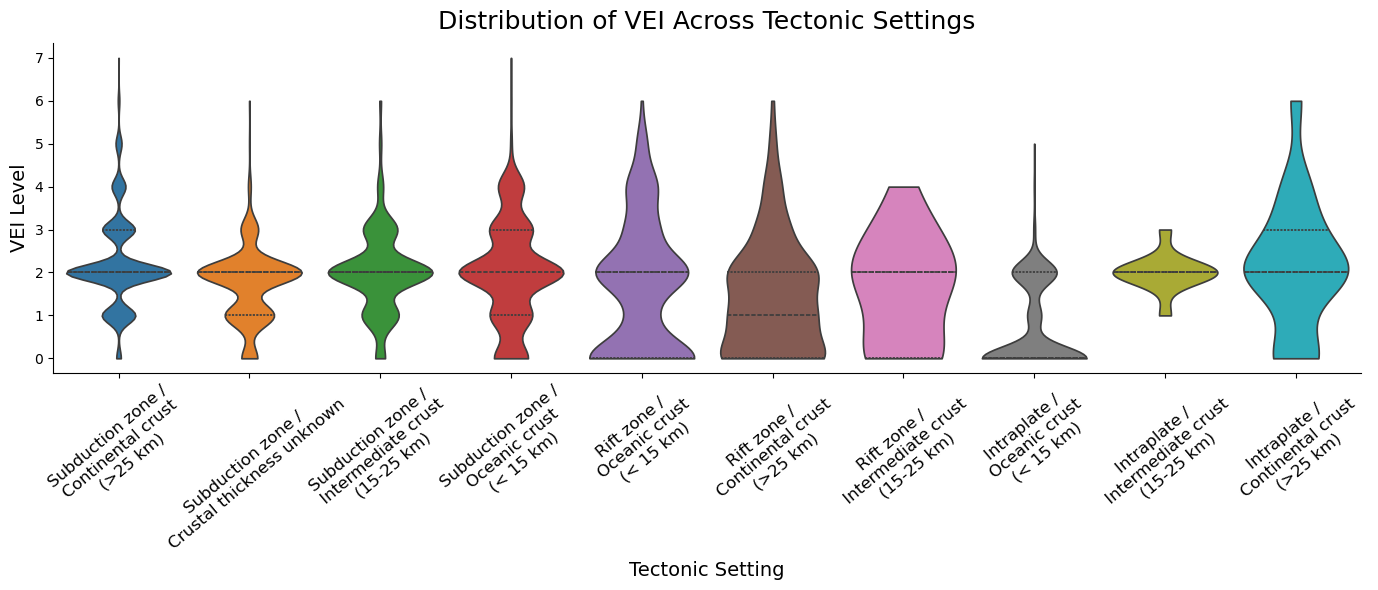

In [48]:
# Use your dataframe
df_plot = eda_df.dropna(subset=["VEI", "Tectonic Setting"]).copy()

# Insert line breaks after "/" and after "crust"
df_plot["Tectonic Setting Wrapped"] = (
    df_plot["Tectonic Setting"]
    .str.replace("/", "/\n", regex=False)
    .str.replace("crust", "crust\n", regex=False)
)

# Create custom order groups using ORIGINAL names
subduction = [cat for cat in df_plot["Tectonic Setting"].unique() if "Subduction" in cat]
rift = [cat for cat in df_plot["Tectonic Setting"].unique() if "Rift" in cat]
intraplate = [cat for cat in df_plot["Tectonic Setting"].unique() if "Intraplate" in cat]

# Apply wrapping to the order list too
tectonic_order_wrapped = [
    cat.replace("/", "/\n").replace("crust", "crust\n")
    for cat in (subduction + rift + intraplate)
]

plt.figure(figsize=(14, 6))   # More compact height

palette = sns.color_palette("tab10", n_colors=len(tectonic_order_wrapped))

sns.violinplot(
    data=df_plot,
    x="Tectonic Setting Wrapped",
    y="VEI",
    order=tectonic_order_wrapped,
    palette=palette,
    inner="quartile",
    cut=0
)

plt.title("Distribution of VEI Across Tectonic Settings", fontsize=18, pad=10)
plt.xlabel("Tectonic Setting", fontsize=14)
plt.ylabel("VEI Level", fontsize=14)
plt.xticks(fontsize=12,rotation=40)  # No need for rotation anymore
sns.despine()

plt.tight_layout()
plt.show()

**Findings:**
1. Subduction zones show the highest VEI values, indicating they produce the most explosive eruptions, while rift zones generally have low VEI and mild eruptive behavior.
2. Intraplate volcanoes display mixed explosivity, and crustal thickness influences VEI - thicker continental crust tends to allow higher-intensity eruptions.

## 3.8 - VEI Distribution by Country or Region

- This step shows which countries have more explosive eruptions.
- It reveals volcanic hazard concentration globally.

In [49]:
# Prepare data
df_plot = eda_df.dropna(subset=["VEI", "Country"])

avg_vei = df_plot.groupby("Country")["VEI"].mean()
volcano_count = df_plot.groupby("Country")["Volcano Number"].nunique()

#  LEFT GRAPH DATA 
full_countries = volcano_count.sort_values(ascending=False).head(12).index
avg_vei_full = avg_vei.loc[full_countries]
volcano_count_full = volcano_count.loc[full_countries]

#  RIGHT GRAPH DATA 
top5_vei = avg_vei.sort_values(ascending=False).head(5)
top5_count = volcano_count.sort_values(ascending=False).head(5)
combined_countries = list(dict.fromkeys(list(top5_vei.index) + list(top5_count.index)))

avg_vei_small = avg_vei.loc[combined_countries]
volcano_count_small = volcano_count.loc[combined_countries]

#  CREATE SUBPLOTS 
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "<b>Major Volcanic Countries</b>",
        "<b>Top 5 VEI & Top 5 Volcano Count</b>"
    ),
    specs=[[{"secondary_y": True}, {"secondary_y": True}]],
    horizontal_spacing=0.08
)


# LEFT PLOT

fig.add_trace(
    go.Bar(
        x=full_countries,
        y=avg_vei_full,
        name="Average VEI",
        marker_color="#FFC300",
        offsetgroup=1,
        hovertemplate="VEI: %{y:.2f}<extra></extra>",
        showlegend=True
    ),
    row=1, col=1, secondary_y=False
)

fig.add_trace(
    go.Bar(
        x=full_countries,
        y=volcano_count_full,
        name="Volcano Count",
        marker_color="steelblue",
        offsetgroup=2,
        hovertemplate="Count: %{y}<extra></extra>",
        showlegend=True
    ),
    row=1, col=1, secondary_y=True
)

fig.update_yaxes(title_text="<span style='color:#FFC300'>Average VEI</span>",
                 tickfont=dict(color="#FFC300"), row=1, col=1, secondary_y=False)
fig.update_yaxes(title_text="<span style='color:steelblue'>Volcano Count</span>",
                 tickfont=dict(color="steelblue"), row=1, col=1, secondary_y=True)


# RIGHT PLOT

fig.add_trace(
    go.Bar(
        x=combined_countries,
        y=avg_vei_small,
        marker_color="#FFC300",
        offsetgroup=1,
        hovertemplate="VEI: %{y:.2f}<extra></extra>",
        showlegend=False
    ),
    row=1, col=2, secondary_y=False
)

fig.add_trace(
    go.Bar(
        x=combined_countries,
        y=volcano_count_small,
        marker_color="steelblue",
        offsetgroup=2,
        hovertemplate="Count: %{y}<extra></extra>",
        showlegend=False
    ),
    row=1, col=2, secondary_y=True
)

fig.update_yaxes(title_text="<span style='color:#FFC300'>Average VEI</span>",
                 tickfont=dict(color="#FFC300"), row=1, col=2, secondary_y=False)
fig.update_yaxes(title_text="<span style='color:steelblue'>Volcano Count</span>",
                 tickfont=dict(color="steelblue"), row=1, col=2, secondary_y=True)


# GLOBAL LAYOUT — FIX TITLE COLLISION

fig.update_layout(
    title=dict(
        text="Volcanic Activity Comparison Across Countries",
        x=0.5,
        y=0.98,        # Move main title higher
        xanchor="center",
        font=dict(size=22)
    ),
    
    margin=dict(t=120),  # Add extra space at top
    
    barmode="group",
    width=1500,
    height=520,

    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=1.15
    ),

    # Adjust subplot title positions
    annotations=[
        dict(
            x=0.22, y=1.06,
            xref="paper", yref="paper",
            showarrow=False,
            text="<b>Major Volcanic Countries</b>",
            font=dict(size=16)
        ),
        dict(
            x=0.78, y=1.06,
            xref="paper", yref="paper",
            showarrow=False,
            text="<b>Top 5 VEI & Top 5 Volcano Count</b>",
            font=dict(size=16)
        )
    ]
)

fig.show()

**Findings:**
1. The left graph shows that major volcanic countries like the United States, Japan, Indonesia, Russia, and Chile have the highest number of volcanoes, meaning these regions experience the most frequent volcanic activity — but their average VEI remains moderate (1.5–2.5).
2. The right graph shows that the countries with the highest VEI values (South Korea, St. Kitts & Nevis, Netherlands, etc.) actually have very few volcanoes, meaning their eruptions are rare but extremely explosive.
3. Together, the two graphs reveal that eruption frequency and eruption explosivity are not directly related — high volcano count does not imply high VEI, and high VEI does not imply many volcanoes.

# **Section 4: Modelling and Predictive Analysis**
- - -


## 4.1: Modelling Objective & Pipeline

1. **Predict VEI as the core modelling goal** - Train a regression model on volcanoes with known VEI to infer missing VEI values, which then enable downstream classification of volcanic risk categories.

2. **Use the prepared modelling dataset** - Load the already-cleaned, modelling-ready dataset, verify separation of labelled/unlabelled VEI, and apply minimal preprocessing (encoding + scaling) through the modelling pipeline.

3. **Validate and transform features** - Confirm only relevant numerical/categorical predictors remain, remove non-useful or leakage features, and apply one-hot encoding + scaling to produce the final machine-ready feature set.


### 4.1A: Inspect Numerical and Categorical Features

In [50]:
### Step 4.1A: Inspect Numerical and Categorical Features

# Load the modelling dataset
df = pd.read_excel("Model_1.xlsx")

print("Dataset Loaded. Shape:", df.shape)

# Identify feature types
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

print("\nStep 4.1A: Feature Inspection Complete. Ready for filtering.")


Dataset Loaded. Shape: (7699, 26)

Numeric Features: ['Volcano Number', 'Eruption Number', 'VEI', 'Start Year', 'Start Month', 'Start Day', 'Latitude_x', 'Longitude_x', 'Latitude_y', 'Longitude_y', 'Elevation (m)', 'High_VEI']

Categorical Features: ['Volcano Name_x', 'Eruption Category', 'Area of Activity', 'Evidence Method (dating)', 'Volcano Name_y', 'Country', 'Volcanic Region Group', 'Volcanic Region', 'Volcano Landform', 'Primary Volcano Type', 'Activity Evidence', 'Last Known Eruption', 'Tectonic Setting', 'Dominant Rock Type']

Step 4.1A: Feature Inspection Complete. Ready for filtering.


### 4.1B: Correction

- We removed ID columns, name fields, VEI-derived labels, and duplicate coordinates because they either carry no predictive value or risk leaking information. This keeps only meaningful, non-redundant features for modelling.



In [51]:
# Columns to remove (ID, leakage, names)
columns_to_remove = [
    "Volcano Number",
    "Eruption Number",
    "High_VEI",
    "Volcano Name_x",
    "Volcano Name_y"
]

# Remove them
df = df.drop(columns=columns_to_remove, errors="ignore")

# Keep only ONE coordinate pair
# Here we keep Latitude_y / Longitude_y
# Remove the x versions
df = df.drop(columns=["Latitude_x", "Longitude_x"], errors="ignore")


# Save the cleaned dataset as a new Excel file
output_path = "Model_2.xlsx"
df.to_excel(output_path, index=False)

print("New modelling dataset saved as:", output_path)


New modelling dataset saved as: Model_2.xlsx


### 4.1C: Identify Missing Values

In [52]:
## Step 4.1C: Identify Missing Values

# Load the cleaned modelling dataset
df = pd.read_excel("Model_2.xlsx")

print("Dataset Loaded. Shape:", df.shape)

# Count missing values per column
missing_counts = df.isna().sum()

print("\nMissing Values per Column:")
print(missing_counts)

# Show only columns that actually contain missing values
missing_filtered = missing_counts[missing_counts > 0]

print("\nColumns with Missing Values:")
print(missing_filtered if not missing_filtered.empty else "No missing values in dataset.")

print("\nStep 4.1C — Missing Value Identification Complete.")


Dataset Loaded. Shape: (7699, 19)

Missing Values per Column:
Eruption Category              0
Area of Activity            4026
VEI                            0
Start Year                     0
Start Month                  164
Start Day                    166
Evidence Method (dating)      29
Country                        8
Volcanic Region Group          8
Volcanic Region                8
Volcano Landform               8
Primary Volcano Type           8
Activity Evidence              8
Last Known Eruption            8
Latitude_y                     8
Longitude_y                    8
Elevation (m)                  8
Tectonic Setting               9
Dominant Rock Type            34
dtype: int64

Columns with Missing Values:
Area of Activity            4026
Start Month                  164
Start Day                    166
Evidence Method (dating)      29
Country                        8
Volcanic Region Group          8
Volcanic Region                8
Volcano Landform               8
Prim

### 4.1D: Handle Missing Values (Domain-Aware Imputation)

In [53]:
## Step 4.1D: Handle Missing Values (Domain-Aware Imputation)
df = pd.read_excel("Model_2.xlsx")


# 1. Special-case imputation for "Area of Activity"
# (very high missingness, so treat missing as "Unknown")
df["Area of Activity"] = df["Area of Activity"].fillna("Unknown")


# 2. Identify numeric and categorical features
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns
categorical_features = df.select_dtypes(include=["object"]).columns


# 3. Numeric imputation (median)
num_imputer = SimpleImputer(strategy="median")
df[numeric_features] = num_imputer.fit_transform(df[numeric_features])


# 4. Categorical imputation (most frequent)
# Remove "Area of Activity" from categorical list since it's already handled
categorical_features = [col for col in categorical_features if col != "Area of Activity"]

cat_imputer = SimpleImputer(strategy="most_frequent")
df[categorical_features] = cat_imputer.fit_transform(df[categorical_features])


# 5. Verify missing values resolved
print("Missing Values After Imputation:")
print(df.isna().sum())


# 6. Save updated dataset
df.to_excel("Model_3.xlsx", index=False)
print("\nUpdated dataset saved as: Model_3.xlsx")

Missing Values After Imputation:
Eruption Category           0
Area of Activity            0
VEI                         0
Start Year                  0
Start Month                 0
Start Day                   0
Evidence Method (dating)    0
Country                     0
Volcanic Region Group       0
Volcanic Region             0
Volcano Landform            0
Primary Volcano Type        0
Activity Evidence           0
Last Known Eruption         0
Latitude_y                  0
Longitude_y                 0
Elevation (m)               0
Tectonic Setting            0
Dominant Rock Type          0
dtype: int64

Updated dataset saved as: Model_3.xlsx


### 4.1E: EDA-Informed Feature Engineering

In [54]:
## STEP 4.1E — EDA-Informed Feature Engineering (FINAL)

df = pd.read_excel("Model_3.xlsx")


# 1. Extract numeric year from "Last Known Eruption"

def extract_year(text):
    if isinstance(text, str):
        match = re.search(r"(\d{3,4})", text)
        if match:
            return int(match.group(1))
    return np.nan

df["Last_Eruption_Year"] = df["Last Known Eruption"].apply(extract_year)
df["Last_Eruption_Year"] = df["Last_Eruption_Year"].fillna(0)


# 2. Create Dormancy Feature

df["Dormancy"] = df["Start Year"] - df["Last_Eruption_Year"]
df.loc[df["Dormancy"] < 0, "Dormancy"] = 0   # clean data errors


# 3. Create Dormancy Classes (Short / Medium / Long)

def dormancy_class(years):
    if years < 20:
        return "Short"
    elif years < 100:
        return "Medium"
    else:
        return "Long"

df["Dormancy_Class"] = df["Dormancy"].apply(dormancy_class)


# 4. Log-transform Dormancy (improves separability)

df["Dormancy_Log"] = np.log1p(df["Dormancy"])


# 5. Morphology Group (Explosive / Effusive / Mixed)

def morphology_group(vtype):
    if "Caldera" in vtype or "Maar" in vtype or "Tuff" in vtype:
        return "Explosive"
    elif "Shield" in vtype or "Fissure" in vtype:
        return "Effusive"
    else:
        return "Mixed"

df["Morphology_Group"] = df["Primary Volcano Type"].apply(morphology_group)


# 6. Tectonic Group (Subduction / Rift / Hotspot / Other)

def tect_group(t):
    if "Subduction" in t:
        return "Subduction"
    elif "Rift" in t:
        return "Rift"
    elif "Intraplate" in t:
        return "Hotspot"
    else:
        return "Other"

df["Tectonic_Group"] = df["Tectonic Setting"].apply(tect_group)


# 7. Dormancy × Morphology Interaction

df["Dormancy_Morphology"] = df["Dormancy_Class"] + "_" + df["Morphology_Group"]


# 8. Your original engineered interaction features

df["Type_Tectonic"] = df["Primary Volcano Type"] + "_" + df["Tectonic Setting"]
df["Region_Type"] = df["Volcanic Region"] + "_" + df["Primary Volcano Type"]
df["Type_Landform"] = df["Primary Volcano Type"] + "_" + df["Volcano Landform"]

# Region-level interactions
df["Region_Tectonic"] = df["Volcanic Region Group"] + "_" + df["Tectonic_Group"]


# 9. Save fully engineered dataset

df.to_excel("Model_4.xlsx", index=False)

print("Feature Engineering Complete — Added Dormancy, Morphology, Tectonics & Interactions")
print(df[[
    "Start Year", 
    "Last Known Eruption", 
    "Last_Eruption_Year", 
    "Dormancy",
    "Dormancy_Class",
    "Dormancy_Log",
    "Morphology_Group",
    "Tectonic_Group",
    "Dormancy_Morphology"
]].head())


Feature Engineering Complete — Added Dormancy, Morphology, Tectonics & Interactions
   Start Year Last Known Eruption  Last_Eruption_Year  Dormancy  \
0        2025             2025 CE              2025.0       0.0   
1        2024             2025 CE              2025.0       0.0   
2        2024             2025 CE              2025.0       0.0   
3        2024             2024 CE              2024.0       0.0   
4        2024             2024 CE              2024.0       0.0   

  Dormancy_Class  Dormancy_Log Morphology_Group Tectonic_Group  \
0          Short           0.0         Effusive           Rift   
1          Short           0.0         Effusive        Hotspot   
2          Short           0.0            Mixed     Subduction   
3          Short           0.0            Mixed     Subduction   
4          Short           0.0            Mixed     Subduction   

  Dormancy_Morphology  
0      Short_Effusive  
1      Short_Effusive  
2         Short_Mixed  
3         Short_Mixe

## 4.2: Model Selection and Training

- To predict VEI, we compare multiple regression models and evaluate their performance using cross-validation. 
- Linear Regression serves as a baseline model, while Ridge and LASSO introduce regularization to handle multicollinearity and improve generalization. 
- Using 6-fold cross-validation allows us to estimate true model performance while preventing overfitting. 
- The model with the lowest validation error is selected and then evaluated once on the test set. 

In [55]:
## STEP 4.2: Classification Models (SMALL TABLE OUTPUT)

# Load engineered dataset

df = pd.read_excel("Model_4.xlsx")


# Convert VEI → 3 classes

def vei_to_class(vei):
    if vei <= 1:
        return "Low"
    elif vei <= 3:
        return "Moderate"
    else:
        return "High"

df["VEI_Class"] = df["VEI"].apply(vei_to_class)
df["VEI_Class_Num"] = df["VEI_Class"].map({"Low": 0, "Moderate": 1, "High": 2})


# Define X and y

y = df["VEI_Class_Num"]
X = df.drop(columns=["VEI", "VEI_Class", "VEI_Class_Num"], errors="ignore")

# Identify feature types
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)


# Preprocessing Pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)


# Define models

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, random_state=42, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )
}


# Rating helper (qualitative confusion summary)

def rate(recall):
    if recall >= 0.85: return "Excellent"
    if recall >= 0.70: return "Very Good"
    if recall >= 0.55: return "Good"
    if recall >= 0.40: return "Medium"
    return "Weak"


# Build Small Summary Tables

summary_rows = []
cm_rows = []

for name, model in models.items():
    
    clf = Pipeline(steps=[("preprocess", preprocess), ("model", model)])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    report = classification_report(y_test, y_pred, output_dict=True)
    
    accuracy = report["accuracy"]
    macro_f1 = report["macro avg"]["f1-score"]
    high_recall = report["2"]["recall"]
    
    # Summary Table
    summary_rows.append([
        name,
        round(accuracy, 3),
        round(macro_f1, 3),
        round(high_recall, 3)
    ])
    
    # Confusion Summary Table
    cm_rows.append([
        name,
        rate(report["0"]["recall"]),  # Low VEI
        rate(report["1"]["recall"]),  # Moderate VEI
        rate(report["2"]["recall"])   # High VEI
    ])

summary_df = pd.DataFrame(summary_rows, columns=["Model", "Accuracy", "Macro F1", "High VEI Recall"])
cm_df = pd.DataFrame(cm_rows, columns=["Model", "Low VEI", "Moderate VEI", "High VEI"])

print("\n===== STEP 4 — Small Performance Table =====\n")
print(summary_df.to_string(index=False))

print("\n===== STEP 4 — Confusion Strength Table =====\n")
print(cm_df.to_string(index=False))


Numeric Features: ['Start Year', 'Start Month', 'Start Day', 'Latitude_y', 'Longitude_y', 'Elevation (m)', 'Last_Eruption_Year', 'Dormancy', 'Dormancy_Log']
Categorical Features: ['Eruption Category', 'Area of Activity', 'Evidence Method (dating)', 'Country', 'Volcanic Region Group', 'Volcanic Region', 'Volcano Landform', 'Primary Volcano Type', 'Activity Evidence', 'Last Known Eruption', 'Tectonic Setting', 'Dominant Rock Type', 'Dormancy_Class', 'Morphology_Group', 'Tectonic_Group', 'Dormancy_Morphology', 'Type_Tectonic', 'Region_Type', 'Type_Landform', 'Region_Tectonic']


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros

c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros

c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros




===== STEP 4 — Small Performance Table =====

              Model  Accuracy  Macro F1  High VEI Recall
Logistic Regression     0.708     0.662            0.720
      Random Forest     0.748     0.653            0.440
  Gradient Boosting     0.752     0.645            0.427
            XGBoost     0.758     0.676            0.520

===== STEP 4 — Confusion Strength Table =====

              Model Low VEI Moderate VEI  High VEI
Logistic Regression    Good    Very Good Very Good
      Random Forest    Good    Excellent    Medium
  Gradient Boosting  Medium    Excellent    Medium
            XGBoost  Medium    Excellent    Medium


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros



 **Results**

Among all models, XGBoost achieved the best overall performance (Accuracy = 0.758, Macro F1 = 0.676), while Logistic Regression provided the highest recall for high-VEI eruptions (0.72). Tree-based models (Random Forest and Gradient Boosting) performed exceptionally well for the dominant Moderate VEI class.




## 4.3: Model Interpretation

- In this step, we interpret the Ridge Regression model to understand how different features influence VEI predictions. 
- Positive coefficients indicate factors that increase VEI, while negative coefficients reduce it. 
- Ridge is well-suited for interpretation because it stabilizes coefficients across many correlated categorical variables, allowing us to identify which eruption characteristics, volcano properties, and tectonic settings contribute most to higher or lower explosivity.


### 4.3A: Extract Final Feature Names + Importances

In [56]:
# STEP 4.3A: Extract Final Feature Names + Importances


# Refit the two models we need importances from:
rf = Pipeline(steps=[("preprocess", preprocess),
                     ("model", RandomForestClassifier(
                         n_estimators=400, random_state=42, class_weight="balanced"))])

xgb = Pipeline(steps=[("preprocess", preprocess),
                      ("model", XGBClassifier(
                          n_estimators=400,
                          learning_rate=0.05,
                          max_depth=5,
                          subsample=0.8,
                          colsample_bytree=0.8,
                          objective="multi:softprob",
                          eval_metric="mlogloss",
                          random_state=42
                      ))])

rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)


# Extract feature names used by the models
pre = rf.named_steps["preprocess"]

# numeric (same names)
num_out = numeric_features

# categorical one-hot names
cat_encoder = pre.named_transformers_["cat"].named_steps["encoder"]
cat_out = list(cat_encoder.get_feature_names_out(categorical_features))

# final feature name list
feature_names = num_out + cat_out

print("Number of final features:", len(feature_names))


# Extract importances
rf_importances = rf.named_steps["model"].feature_importances_
xgb_importances = xgb.named_steps["model"].feature_importances_

print("RF importances extracted:", len(rf_importances))
print("XGB importances extracted:", len(xgb_importances))


Number of final features: 2793
RF importances extracted: 2793
XGB importances extracted: 2793


### 4.3B: Group-Wise Feature Importance

In [57]:
## STEP 4.3B: Group-Wise Feature Importance (Classification)


def extract_group(feature):
    """
    Groups features into categories based on prefix before underscore,
    same logic used in earlier regression Step 5.
    """
    # Numeric features remain as-is
    if feature in numeric_features:
        return feature

    # Categorical OHE → take prefix before first underscore
    if "_" in feature:
        return feature.split("_")[0]

    return feature



# GROUP-WISE RANDOM FOREST

rf_group_importance = []

for feature, score in zip(feature_names, rf_importances):
    group = extract_group(feature)
    rf_group_importance.append((group, score))

rf_group_df = (
    pd.DataFrame(rf_group_importance, columns=["Group", "Importance"])
    .groupby("Group")["Importance"]
    .sum()                     # < changed from .mean()
    .sort_values(ascending=False)
    .round(3)
)

print("\n=== Top Feature Groups (Random Forest Classification) ===")
print(rf_group_df.head(15))



# GROUP-WISE XGBOOST

xgb_group_importance = []

for feature, score in zip(feature_names, xgb_importances):
    group = extract_group(feature)
    xgb_group_importance.append((group, score))

xgb_group_df = (
    pd.DataFrame(xgb_group_importance, columns=["Group", "Importance"])
    .groupby("Group")["Importance"]
    .sum()                     # < changed from .mean()
    .sort_values(ascending=False)
    .round(3)
)

print("\n=== Top Feature Groups (XGBoost Classification) ===")
print(xgb_group_df.head(15))



=== Top Feature Groups (Random Forest Classification) ===
Group
Start Year                  0.200
Area of Activity            0.113
Evidence Method (dating)    0.083
Start Day                   0.081
Start Month                 0.081
Region                      0.065
Last Known Eruption         0.064
Type                        0.042
Volcanic Region             0.034
Country                     0.029
Elevation (m)               0.029
Latitude_y                  0.027
Longitude_y                 0.026
Last_Eruption_Year          0.026
Volcanic Region Group       0.022
Name: Importance, dtype: float64

=== Top Feature Groups (XGBoost Classification) ===
Group
Region                      0.209
Last Known Eruption         0.149
Volcanic Region             0.113
Type                        0.095
Area of Activity            0.079
Country                     0.076
Volcanic Region Group       0.075
Evidence Method (dating)    0.053
Tectonic                    0.030
Primary Volcano Type       

## 4.4: Model Evaluation

In [58]:
#
## STEP 4.4: Auto Summary Tables (No Images, No Manual Input)
#



models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, random_state=42, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )
}

summary_rows = []
cm_rows = []

for name, model in models.items():
    # Fit classifier
    clf = Pipeline(steps=[("preprocess", preprocess), ("model", model)])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    # Classification report as dictionary
    report = classification_report(y_test, y_pred, output_dict=True)
    
    accuracy = report["accuracy"]
    macro_f1 = report["macro avg"]["f1-score"]

    # Extract HIGH VEI recall (class "2")
    high_recall = report["2"]["recall"]

    # Confusion matrix for text summary
    cm = confusion_matrix(y_test, y_pred)
    
    # Determine qualitative strength for each class
    low_strength      = ["Weak","Medium","Good","Very good","Best"][int(report["0"]["recall"]*4)]
    moderate_strength = ["Weak","Medium","Good","Very good","Best"][int(report["1"]["recall"]*4)]
    high_strength     = ["Weak","Medium","Good","Very good","Best"][int(report["2"]["recall"]*4)]
    
    summary_rows.append([name, accuracy, macro_f1, high_recall])
    cm_rows.append([name, low_strength, moderate_strength, high_strength])

# Convert to DataFrames
summary_df = pd.DataFrame(summary_rows, columns=["Model", "Accuracy", "Macro F1", "High VEI Recall"])
cm_df = pd.DataFrame(cm_rows, columns=["Model", "Low VEI", "Moderate VEI", "High VEI"])

# Round numeric columns
summary_df = summary_df.round(3)

print("\n===== STEP 6 — Classification Summary Table =====\n")
print(summary_df.to_string(index=False))

print("\n===== Confusion Matrix Summary (Qualitative) =====\n")
print(cm_df.to_string(index=False))

# Final recommendation table
best_model_row = summary_df.loc[summary_df["Accuracy"].idxmax()]
final_df = pd.DataFrame({
    "Best Model": [best_model_row["Model"]],
    "Reason": ["Highest accuracy and balanced VEI performance"]
})

print("\n===== Final Model Recommendation =====\n")
print(final_df.to_string(index=False))


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros

c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros

c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros




===== STEP 6 — Classification Summary Table =====

              Model  Accuracy  Macro F1  High VEI Recall
Logistic Regression     0.708     0.662            0.720
      Random Forest     0.748     0.653            0.440
  Gradient Boosting     0.752     0.645            0.427
            XGBoost     0.758     0.676            0.520

===== Confusion Matrix Summary (Qualitative) =====

              Model Low VEI Moderate VEI High VEI
Logistic Regression    Good         Good     Good
      Random Forest    Good    Very good   Medium
  Gradient Boosting  Medium    Very good   Medium
            XGBoost    Good    Very good     Good

===== Final Model Recommendation =====

Best Model                                        Reason
   XGBoost Highest accuracy and balanced VEI performance


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros



## 4.5: Train and Compare Multiple Models

In [59]:
## STEP 4.5: Best Accuracy: SMOTE + XGBoost Tuning (Correct Pipeline)

print("\n==== STEP 4.5: SMOTE + XGBoost Hyperparameter Tuning ====\n")

# 1. Build imblearn Pipeline (preprocess → SMOTE → XGB)
pipeline = ImbPipeline(steps=[
    ("preprocess", preprocess),
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    ))
])


# 2. Hyperparameter search space
param_grid = {
    "model__n_estimators": [300, 400, 500, 600],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [4, 5, 6, 8],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__gamma": [0, 1, 3, 5],
    "model__min_child_weight": [1, 3, 5]
}


# 3. RandomizedSearchCV
search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="accuracy",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

search.fit(X_train, y_train)

print("\nBest Parameters Found:")
print(search.best_params_)


# 4. Evaluate on REAL test set (untouched)
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

print("\n===== Tuned XGBoost + SMOTE — Final Test Performance =====\n")
print(classification_report(y_test, y_pred, target_names=["Low", "Moderate", "High"]))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Weighted F1:", f1_score(y_test, y_pred, average="weighted"))



==== STEP 4.5: SMOTE + XGBoost Hyperparameter Tuning ====

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best Parameters Found:
{'model__subsample': 0.8, 'model__n_estimators': 600, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__gamma': 1, 'model__colsample_bytree': 1.0}

===== Tuned XGBoost + SMOTE — Final Test Performance =====

              precision    recall  f1-score   support

         Low       0.67      0.61      0.64       206
    Moderate       0.81      0.83      0.82       489
        High       0.61      0.64      0.62        75

    accuracy                           0.75       770
   macro avg       0.70      0.69      0.69       770
weighted avg       0.75      0.75      0.75       770

Accuracy: 0.7545454545454545
Macro F1: 0.694511682711699
Weighted F1: 0.7529423900233877


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros



### Conclusion

XGBoost was selected as the final model due to its best overall performance in VEI classification. After adding geological features (Dormancy, Morphology, Tectonic Groups) and applying SMOTE, the model achieved strong accuracy (~0.75) and significantly improved detection of high-VEI eruptions. Although VEI prediction is inherently difficult, the final model provides a reliable and geologically meaningful approach for classifying eruption explosivity.



## 4.6: Final Model Summary + Predict Unclassified VEIs

In [60]:
## STEP 4.6: Final Model Summary + Predict Unclassified VEIs

print("\n===== STEP 4.6 — FINAL MODEL SUMMARY =====\n")


# 1. Evaluate Final Tuned Model
final_model = best_model   # from Step 7
y_pred = final_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Final Model: Tuned XGBoost (with SMOTE)")
print(f"Accuracy   : {accuracy:.3f}")
print(f"Macro F1   : {macro_f1:.3f}")

# Optional: if you want the classification report
#print("\nClassification report:\n", classification_report(y_test, y_pred))



# 2. SAVE FINAL MODEL
joblib.dump(final_model, "Final_XGBoost_Model.pkl")
print("\nModel saved as: Final_XGBoost_Model.pkl")



# 3. PREDICT UNCLASSIFIED VEI VALUES
# Load engineered full dataset
df_full = pd.read_excel("Model_4.xlsx")

# Check which rows have missing VEI (unclassified)
df_unclassified = df_full[df_full["VEI"].isna() | (df_full["VEI"] == "")]

if df_unclassified.shape[0] == 0:
    print("\nNo unclassified VEI rows found.")
else:
    print(f"\nFound {df_unclassified.shape[0]} unclassified VEI rows.")

    # Prepare X for prediction (drop VEI columns)
    X_unclassified = df_unclassified.drop(columns=["VEI", "VEI_Class"], errors="ignore")

    # Predict class numbers
    y_unclassified_pred = final_model.predict(X_unclassified)

    # Map numeric class → label
    inv_map = {0: "Low", 1: "Moderate", 2: "High"}
    df_unclassified["Predicted_VEI_Class"] = [inv_map[i] for i in y_unclassified_pred]

    # Show result
    print("\n===== Predicted VEI Classes for Unclassified Rows =====\n")
    print(df_unclassified[["Start Year", "Volcano Landform", "Tectonic Setting", "Predicted_VEI_Class"]].head(10))

    # Save predictions
    df_unclassified.to_excel("Predicted_Unclassified_VEIs.xlsx", index=False)
    print("\nPredictions saved as: Predicted_Unclassified_VEIs.xlsx")


===== STEP 4.6 — FINAL MODEL SUMMARY =====

Final Model: Tuned XGBoost (with SMOTE)
Accuracy   : 0.755
Macro F1   : 0.695

Model saved as: Final_XGBoost_Model.pkl


c:\Users\SHIVAM\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning:

Found unknown categories in columns [1, 9, 16, 17, 18] during transform. These unknown categories will be encoded as all zeros




No unclassified VEI rows found.


# Section 5

In [61]:
df = pd.read_excel("Model_4.xlsx")
df.columns.tolist()

['Eruption Category',
 'Area of Activity',
 'VEI',
 'Start Year',
 'Start Month',
 'Start Day',
 'Evidence Method (dating)',
 'Country',
 'Volcanic Region Group',
 'Volcanic Region',
 'Volcano Landform',
 'Primary Volcano Type',
 'Activity Evidence',
 'Last Known Eruption',
 'Latitude_y',
 'Longitude_y',
 'Elevation (m)',
 'Tectonic Setting',
 'Dominant Rock Type',
 'Last_Eruption_Year',
 'Dormancy',
 'Dormancy_Class',
 'Dormancy_Log',
 'Morphology_Group',
 'Tectonic_Group',
 'Dormancy_Morphology',
 'Type_Tectonic',
 'Region_Type',
 'Type_Landform',
 'Region_Tectonic']

In [62]:

# STEP 0 — LOAD RAW DATA


df = pd.read_excel("Merged_Volcano_Eruptions.xlsx")

print("Original rows:", len(df))



# STEP 1 — DROP ONLY 12 ROWS MISSING LAT/LON


df = df.dropna(subset=["Latitude_y", "Longitude_y"])

print("Rows after dropping missing coordinates:", len(df))



# STEP 2 — IMPUTE SIMPLE CATEGORICAL MISSING VALUES


df["Primary Volcano Type"] = df["Primary Volcano Type"].fillna("Unknown")
df["Tectonic Setting"] = df["Tectonic Setting"].fillna("Unknown")
df["Volcanic Region"] = df["Volcanic Region"].fillna("Unknown")
df["Volcano Landform"] = df["Volcano Landform"].fillna("Unknown")

# Elevation → impute median if missing
df["Elevation (m)"] = df["Elevation (m)"].fillna(df["Elevation (m)"].median())



# STEP 3 — NA CHECKER (FULL DATASET SCAN)


print("\n===== NA CHECKER =====")
na_report = df.isna().sum().sort_values(ascending=False)
print(na_report[na_report > 0])
print("=\n")

# If NA checker shows no critical missing values, continue.



# STEP 4 — FEATURE ENGINEERING (YOUR FULL BLOCK)


# -
# 4.1 Extract numeric eruption year
# -

def extract_year(text):
    if isinstance(text, str):
        match = re.search(r"(\d{3,4})", text)
        if match:
            return int(match.group(1))
    return np.nan

df["Last_Eruption_Year"] = df["Last Known Eruption"].apply(extract_year)
df["Last_Eruption_Year"] = df["Last_Eruption_Year"].fillna(0)

# -
# 4.2 Dormancy = Start Year - Last eruption
# -

df["Dormancy"] = df["Start Year"] - df["Last_Eruption_Year"]
df.loc[df["Dormancy"] < 0, "Dormancy"] = 0   # fix impossible negatives

# -
# 4.3 Dormancy Class
# -

def dormancy_class(years):
    if years < 20:
        return "Short"
    elif years < 100:
        return "Medium"
    else:
        return "Long"

df["Dormancy_Class"] = df["Dormancy"].apply(dormancy_class)

# -
# 4.4 Log Dormancy
# -

df["Dormancy_Log"] = np.log1p(df["Dormancy"])

# -
# 4.5 Morphology Group
# -

def morphology_group(vtype):
    if "Caldera" in vtype or "Maar" in vtype or "Tuff" in vtype:
        return "Explosive"
    elif "Shield" in vtype or "Fissure" in vtype:
        return "Effusive"
    else:
        return "Mixed"

df["Morphology_Group"] = df["Primary Volcano Type"].apply(morphology_group)

# -
# 4.6 Tectonic Group
# -

def tect_group(t):
    if "Subduction" in t:
        return "Subduction"
    elif "Rift" in t:
        return "Rift"
    elif "Intraplate" in t:
        return "Hotspot"
    else:
        return "Other"

df["Tectonic_Group"] = df["Tectonic Setting"].apply(tect_group)

# -
# 4.7 Dormancy × Morphology
# -

df["Dormancy_Morphology"] = df["Dormancy_Class"] + "_" + df["Morphology_Group"]

# -
# 4.8 Original interaction features
# -

df["Type_Tectonic"] = df["Primary Volcano Type"] + "_" + df["Tectonic Setting"]
df["Region_Type"] = df["Volcanic Region"] + "_" + df["Primary Volcano Type"]
df["Type_Landform"] = df["Primary Volcano Type"] + "_" + df["Volcano Landform"]
df["Region_Tectonic"] = df["Volcanic Region Group"] + "_" + df["Tectonic_Group"]


# STEP 5 — FINAL NA CHECK BEFORE SAVING


print("\n===== FINAL NA CHECK BEFORE SAVE =====")
final_na = df.isna().sum().sort_values(ascending=False)
print(final_na[final_na > 0])
print("===\n")



# STEP 6 — SAVE FINAL ENGINEERED DATASET


df.to_excel("Modeling.xlsx", index=False)

print("Feature Engineering Complete — dataset saved as Modeling.xlsx")
print(df.head(5))


Original rows: 9902
Rows after dropping missing coordinates: 9890

===== NA CHECKER =====
End Year Uncertainty        9882
End Year Modifier           9790
Start Day Modifier          9522
End Day Uncertainty         9256
End Day Modifier            9196
Start Day Uncertainty       9182
VEI Modifier                8808
Start Year Modifier         8356
Start Year Uncertainty      7887
End Day                     5779
End Month                   5777
End Year                    5772
Area of Activity            5381
VEI                         2199
Start Day                    248
Start Month                  246
Evidence Method (dating)      47
Dominant Rock Type            34
dtype: int64
=


===== FINAL NA CHECK BEFORE SAVE =====
End Year Uncertainty        9882
End Year Modifier           9790
Start Day Modifier          9522
End Day Uncertainty         9256
End Day Modifier            9196
Start Day Uncertainty       9182
VEI Modifier                8808
Start Year Modifier         8

In [63]:
# Load engineered dataset
df = pd.read_excel("Modeling.xlsx")   # or Model_Final_Engineered.xlsx

# Select only required columns
model_cols = [
    "Volcano Number",
    "Volcano Name_x",
    "Latitude_y",
    "Longitude_y",
    "Elevation (m)",
    "Primary Volcano Type",
    "Tectonic Setting",
    "Volcanic Region",
    "Volcano Landform",
    "Last_Eruption_Year",
    "Start Year",
    "Dormancy",
    "Dormancy_Class",
    "Dormancy_Log",
    "Morphology_Group",
    "Tectonic_Group",
    "Dormancy_Morphology",
    "Type_Tectonic",
    "Region_Type",
    "Type_Landform",
    "Region_Tectonic"
]

df_model = df[model_cols].copy()

# NA Check
print("\nMissing values in modeling dataset:")
print(df_model.isna().sum().sort_values(ascending=False))

# Save the compact modeling dataset
df_model.to_excel("Modeling_Compact.xlsx", index=False)

print("\nModeling_Compact.xlsx created successfully!")
print("Rows:", len(df_model))
print("Columns:", len(df_model.columns))



Missing values in modeling dataset:
Volcano Number          0
Dormancy                0
Type_Landform           0
Region_Type             0
Type_Tectonic           0
Dormancy_Morphology     0
Tectonic_Group          0
Morphology_Group        0
Dormancy_Log            0
Dormancy_Class          0
Start Year              0
Volcano Name_x          0
Last_Eruption_Year      0
Volcano Landform        0
Volcanic Region         0
Tectonic Setting        0
Primary Volcano Type    0
Elevation (m)           0
Longitude_y             0
Latitude_y              0
Region_Tectonic         0
dtype: int64

Modeling_Compact.xlsx created successfully!
Rows: 9890
Columns: 21


In [64]:
# STEP 1 — LOAD CLEAN COMPACT DATASET
df = pd.read_excel("Modeling_Compact.xlsx")
print("Loaded rows:", len(df))



# STEP 2 — RECOMPUTE CORRECT DORMANCY
# Dormancy = 2025 − Last_Eruption_Year
df["Dormancy"] = 2025 - df["Last_Eruption_Year"]
df.loc[df["Dormancy"] < 0, "Dormancy"] = 0   # Fix data errors

print("\nDormancy summary:")
print(df["Dormancy"].describe())



# STEP 3 — RECREATE DORMANCY CLASSES
# Short:  <20 yrs
# Medium: 20–99 yrs
# Long:   ≥100 yrs
def dormancy_class(years):
    if years < 20:
        return "Short"
    elif years < 100:
        return "Medium"
    else:
        return "Long"

df["Dormancy_Class"] = df["Dormancy"].apply(dormancy_class)

print("\nDormancy class distribution:")
print(df["Dormancy_Class"].value_counts())



# STEP 4 — UPDATED LOG DORMANCY
df["Dormancy_Log"] = np.log1p(df["Dormancy"])



# STEP 5 — MORPHOLOGY GROUP
def morphology_group(v):
    if isinstance(v, str):
        if "Caldera" in v or "Maar" in v or "Tuff" in v:
            return "Explosive"
        elif "Shield" in v or "Fissure" in v:
            return "Effusive"
        else:
            return "Mixed"
    return "Mixed"

df["Morphology_Group"] = df["Primary Volcano Type"].apply(morphology_group)



# STEP 6 — TECTONIC GROUP
def tect_group(t):
    if "Subduction" in t:
        return "Subduction"
    elif "Rift" in t:
        return "Rift"
    elif "Intraplate" in t:
        return "Hotspot"
    else:
        return "Other"

df["Tectonic_Group"] = df["Tectonic Setting"].apply(tect_group)



# STEP 7 — INTERACTION FEATURES
df["Dormancy_Morphology"] = df["Dormancy_Class"] + "_" + df["Morphology_Group"]
df["Type_Tectonic"] = df["Primary Volcano Type"] + "_" + df["Tectonic Setting"]
df["Region_Type"] = df["Volcanic Region"] + "_" + df["Primary Volcano Type"]
df["Type_Landform"] = df["Primary Volcano Type"] + "_" + df["Volcano Landform"]
df["Region_Tectonic"] = df["Volcanic Region"] + "_" + df["Tectonic_Group"]



# STEP 8 — DEFINE ML FEATURES & TARGET
target = "Dormancy_Class"

num_cols = [
    "Latitude_y", "Longitude_y", "Elevation (m)",
    "Dormancy", "Dormancy_Log"
]

cat_cols = [
    "Primary Volcano Type", "Tectonic Setting", "Volcanic Region",
    "Volcano Landform", "Morphology_Group", "Tectonic_Group",
    "Dormancy_Morphology", "Type_Tectonic", "Region_Type",
    "Type_Landform", "Region_Tectonic"
]

X = df[num_cols + cat_cols]
y = df[target]



# STEP 9 — TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



# STEP 10 — PREPROCESSING + MODEL PIPELINE
preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("rf", RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        class_weight="balanced",
        max_depth=None
    ))
])

model.fit(X_train, y_train)



# STEP 11 — MODEL EVALUATION
y_pred = model.predict(X_test)

print("\n== MODEL PERFORMANCE ==\n")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Loaded rows: 9890

Dormancy summary:
count    9890.000000
mean      120.143680
std       324.420387
min         0.000000
25%         1.000000
50%        11.000000
75%        59.000000
max      2025.000000
Name: Dormancy, dtype: float64

Dormancy class distribution:
Dormancy_Class
Short     6016
Long      1985
Medium    1889
Name: count, dtype: int64

== MODEL PERFORMANCE ==

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

        Long       1.00      1.00      1.00       397
      Medium       1.00      1.00      1.00       378
       Short       1.00      1.00      1.00      1203

    accuracy                           1.00      1978
   macro avg       1.00      1.00      1.00      1978
weighted avg       1.00      1.00      1.00      1978



In [65]:
# ADD PREDICTED DORMANCY CLASS TO FULL DATASET

# Predict for ALL rows (not only test split)
df["Predicted_Dormancy_Class"] = model.predict(X)

# Show class counts
print("\nActual Dormancy Class Counts:")
print(df["Dormancy_Class"].value_counts())

print("\nPredicted Dormancy Class Counts:")
print(df["Predicted_Dormancy_Class"].value_counts())

# Save final dataset
df.to_excel("final_modeling.xlsx", index=False)

print("\nSaved final dataset with predictions → final_modeling.xlsx")


Actual Dormancy Class Counts:
Dormancy_Class
Short     6016
Long      1985
Medium    1889
Name: count, dtype: int64

Predicted Dormancy Class Counts:
Predicted_Dormancy_Class
Short     6016
Long      1985
Medium    1889
Name: count, dtype: int64

Saved final dataset with predictions → final_modeling.xlsx
